# **Projectwork: Forest cover type prediction**

**Author** Claudio W.  
**Date:** 22.12.2024


---
## **Setup**
Import necessary librarys and set a colour palette used for all plots

In [ ]:
# Basic imports
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import time
from scipy.interpolate import griddata
from joblib import Parallel, delayed
import optuna

# SciKit Learn specific imports
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn import preprocessing
from sklearn import svm
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import cross_val_predict
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from sklearn.ensemble import AdaBoostClassifier
from sklearn.model_selection import KFold

Our color palette:


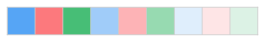

In [16]:
# Enable vectorized graphics
%config InlineBackend.figure_formats = ["svg"]

# Setup plotting
PALETTE = [ (0.341, 0.648, 0.962, 1.0), 
            (0.990, 0.476, 0.494, 1.0), 
            (0.281, 0.749, 0.463, 1.0), 
            (0.629, 0.802, 0.978, 1.0), 
            (0.994, 0.705, 0.715, 1.0), 
            (0.595, 0.858, 0.698, 1.0), 
            (0.876, 0.934, 0.992, 1.0), 
            (0.998, 0.901, 0.905, 1.0), 
            (0.865, 0.952, 0.899, 1.0) ]

# For more color palettes, see here:
# https://seaborn.pydata.org/tutorial/color_palettes.html
# https://matplotlib.org/stable/users/explain/colors/colormaps.html
#PALETTE = sns.color_palette("husl", 8)
#PALETTE = sns.color_palette("viridis", 10)

print("Our color palette:")
sns.palplot(PALETTE, size=0.5)

sns.set_style("whitegrid")
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=PALETTE)
plt.rcParams["figure.dpi"] = 300    # High-res figures (DPI)
plt.rcParams["pdf.fonttype"] = 42   # Editable text in PDF

---
## **Preprocessing**

The following section is about getting an overview of the data and finding out what still needs to be encoded or otherwise changed.

The data is already very well prepared, meaning that all variables are already numerical values, *one-hot-encoding* has already been performed, and there are no NaN values in the entire dataset. Thus no alterations were done to the data.

In [17]:
# Load the data
data = pd.read_csv('data/train.csv')

# Inspect the first few rows
data.head()

,Id,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,1,2596,51,3,258,0,510,221,232,148,...,0,0,0,0,0,0,0,0,0,5
1,2,2590,56,2,212,-6,390,220,235,151,...,0,0,0,0,0,0,0,0,0,5
2,3,2804,139,9,268,65,3180,234,238,135,...,0,0,0,0,0,0,0,0,0,2
3,4,2785,155,18,242,118,3090,238,238,122,...,0,0,0,0,0,0,0,0,0,2
4,5,2595,45,2,153,-1,391,220,234,150,...,0,0,0,0,0,0,0,0,0,5


In [18]:
# Check for missing values
if data.isnull().values.any():
    print("Rows with NaN or NULL values:")
    print(data[data.isnull().any(axis=1)])
else:
    print("No missing values found.")

No missing values found.


In [ ]:
# Check the data types and print the row and corresponding data type if it is not int64
non_int64_columns = [column for column in data.columns if data[column].dtype != np.int64]
if non_int64_columns:
    for column in non_int64_columns:
        print(f"Column '{column}' has type '{data[column].dtype}'")
else:
    print("All columns are of type 'int64'.")

All columns are of type 'int64'.


In [ ]:
# Check if we have any duplicate rows
print("Number of duplicate rows:", data.duplicated().sum())

Number of duplicate rows: 0


In [21]:
# Check how many data points we have for each cover type
cover_type_counts = data['Cover_Type'].value_counts()
print(cover_type_counts)

Cover_Type
5    2160
2    2160
1    2160
7    2160
3    2160
6    2160
4    2160
Name: count, dtype: int64


In [22]:
# Use summary statistics to get an overview of the data
summary = data.describe()
summary

,Id,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
count,15120.00000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,...,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000,15120.000000
mean,7560.50000,2749.322553,156.676653,16.501587,227.195701,51.076521,1714.023214,212.704299,218.965608,135.091997,...,0.045635,0.040741,0.001455,0.006746,0.000661,0.002249,0.048148,0.043452,0.030357,4.000000
std,4364.91237,417.678187,110.085801,8.453927,210.075296,61.239406,1325.066358,30.561287,22.801966,45.895189,...,0.208699,0.197696,0.038118,0.081859,0.025710,0.047368,0.214086,0.203880,0.171574,2.000066
min,1.00000,1863.000000,0.000000,0.000000,0.000000,-146.000000,0.000000,0.000000,99.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,3780.75000,2376.000000,65.000000,10.000000,67.000000,5.000000,764.000000,196.000000,207.000000,106.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000
50%,7560.50000,2752.000000,126.000000,15.000000,180.000000,32.000000,1316.000000,220.000000,223.000000,138.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000
75%,11340.25000,3104.000000,261.000000,22.000000,330.000000,79.000000,2270.000000,235.000000,235.000000,167.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000
max,15120.00000,3849.000000,360.000000,52.000000,1343.000000,554.000000,6890.000000,254.000000,254.000000,248.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,7.000000


---

## **Explorative Data analysis**
**Section: Feature Importance**  
Initially, a Logistic Regression and a Random-Forest are used to extract the most important features. The most important features from both algorithms are then combined. This is done because the dataset contains a large number of features, and it's not possible to plot all of them. For the modeling process, it might also be possible to remove some redundant features. This section is already reaching far into the model building and feature selection phase which is not ideal.

**Section: Plots**  
Consequently, the plots in the following section mostly show only the most important features and their relationship to the target variable, cover-type. The primary goal of the plots is to help understand which features can be used to achieve the best possible prediction. In doing so, I'm paying close attention to the distributions and looking for cases where the target variables have the most distinct distributions.

### **Feature importance**
#### **Logistical regression**

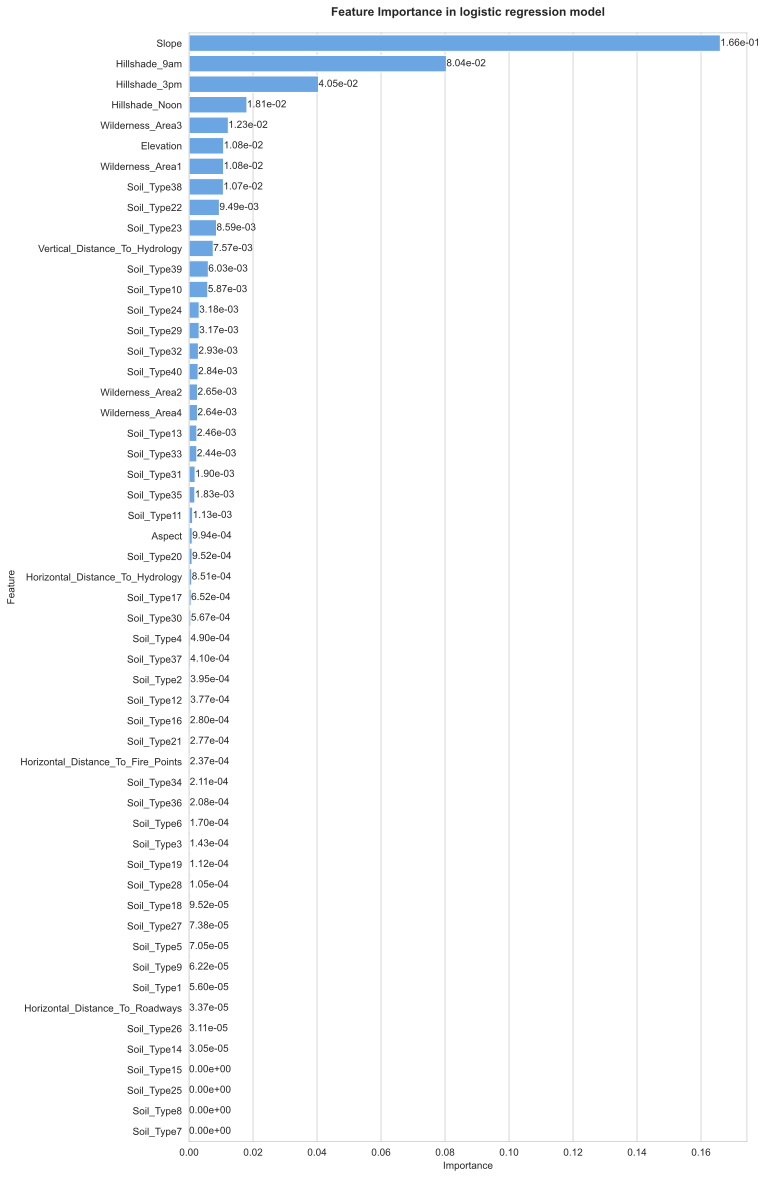

In [ ]:
# Using logistical regression to find the most important features

# Splitting the data into target and features by dropping the columns 'Cover_Type' and 'Id'
X_data = data.drop(columns=['Cover_Type', 'Id'], axis = 1)
Y_data = data['Cover_Type']

# Split the data into training and test sets
X_train, X_test, Y_train, Y_test = train_test_split(X_data, Y_data, test_size=0.2, random_state=420)

# Train a logistic regression model
model = LogisticRegression(max_iter = 1000, 
                           n_jobs = -1, 
                           random_state = 420)
model.fit(X_train, Y_train)

# Get the feature importance which are the coefficients of the model
feature_importance = model.coef_[0]

# Create a DataFrame with the feature importance
logistic_importance_df = pd.DataFrame({'Feature': X_data.columns, 'Importance': feature_importance.flatten()})
# Take the absolut values of the features
logistic_importance_df['Importance'] = logistic_importance_df['Importance'].abs()
# Sort the features according to importance
logistic_importance_df = logistic_importance_df.sort_values(by='Importance', ascending=False)


# Ploting
# Plot the feature importance
plt.figure(figsize=(10, 20))
sns.barplot(data=logistic_importance_df, x='Importance', y='Feature')

# Set title and labels
plt.title("Feature Importance in logistic regression model", fontsize = 12, fontweight='bold', y=1.01)
plt.xlabel("Importance")
plt.ylabel("Feature")

# Write the values in the bars
for index, value in enumerate(logistic_importance_df['Importance']):
    plt.text(value, index, f'{value:.2e}', va='center')

# Show the plot
plt.show()

#### **Random-Forest**

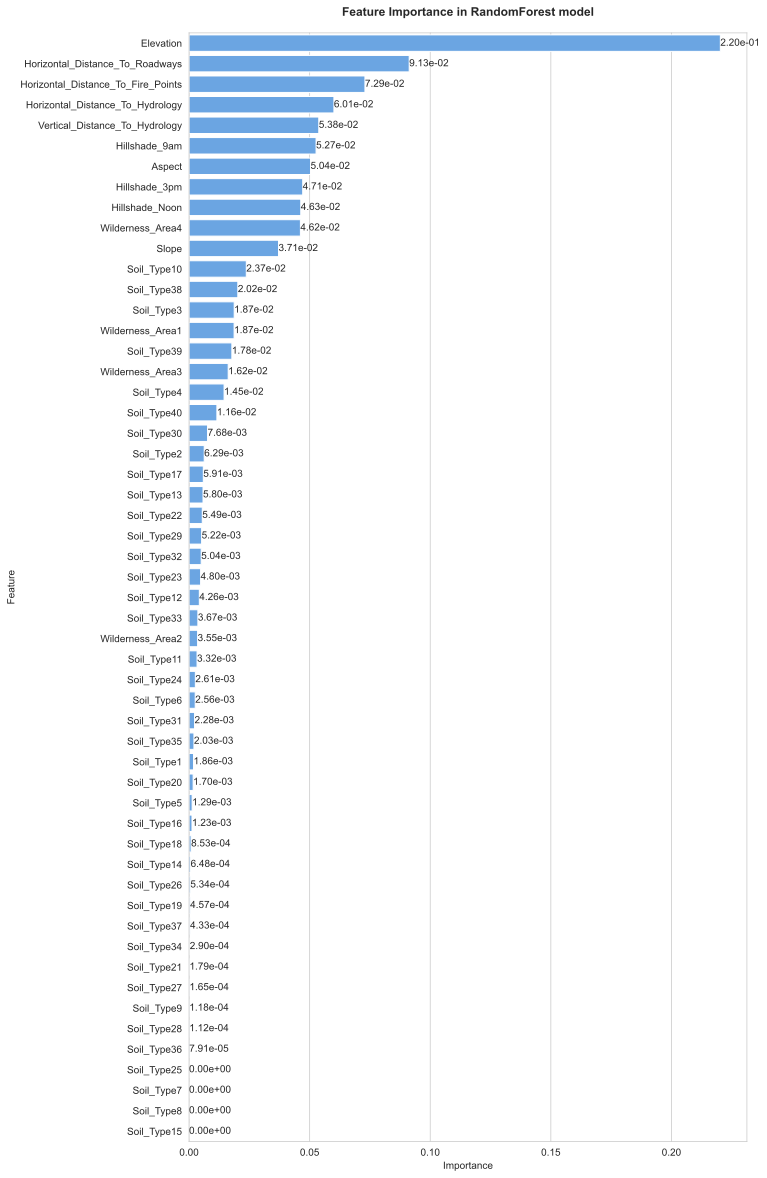

In [ ]:
# Using Random-Forest to find the most important features

# Train a Random-Forest model
forest = RandomForestClassifier(random_state=420,
                                n_jobs = -1)

# Fit the model
forest.fit(X_train, Y_train)

# Get the feature importances 
importances = forest.feature_importances_

# Get the standard deviation of the importances
std = np.std([tree.feature_importances_ for tree in forest.estimators_], axis=0)

# Create a DataFrame with the feature importance
forest_importance_df = pd.DataFrame({'Feature': X_data.columns, 'Importance': importances})
forest_importance_df = forest_importance_df.sort_values(by='Importance', ascending=False)


# Ploting
# Plot the feature importance
plt.figure(figsize = (10, 20))
sns.barplot(data = forest_importance_df, x='Importance', y='Feature')

# Set title and labels
plt.title("Feature Importance in RandomForest model", fontsize = 12, fontweight='bold', y=1.01)
plt.xlabel("Importance")
plt.ylabel("Feature")

# Write the values in the bars
for index, value in enumerate(forest_importance_df['Importance']):
    plt.text(value, index, f'{value:.2e}', va='center')

# Show the plot
plt.show()

#### **Combine the most important features**

In [25]:
# Assign points based on the ranking of features in each model
logistic_importance_df['Points'] = range(len(logistic_importance_df), 0, -1)
forest_importance_df['Points'] = range(len(forest_importance_df), 0, -1)

# Take the first 8 elements of each algorithm dataframe
logistic_top_8 = logistic_importance_df.head(8)
forest_top_8 = forest_importance_df.head(8)

# Combine them by their feature name
combined_top_features = pd.concat([logistic_top_8[['Feature', 'Points']], forest_top_8[['Feature', 'Points']]])
combined_top_features = combined_top_features.groupby('Feature').sum().reset_index()

# Sort the features by the combined points
combined_top_features = combined_top_features.sort_values(by='Points', ascending=False)

# Display the combined top features
print("The most important features according to both models are:")
print("")
print(combined_top_features)

The most important features according to both models are:

                               Feature  Points
1                            Elevation     103
3                        Hillshade_9am     102
2                        Hillshade_3pm      99
8                                Slope      54
7      Horizontal_Distance_To_Roadways      53
5   Horizontal_Distance_To_Fire_Points      52
4                       Hillshade_Noon      51
6     Horizontal_Distance_To_Hydrology      51
10      Vertical_Distance_To_Hydrology      50
12                    Wilderness_Area3      50
0                               Aspect      48
11                    Wilderness_Area1      48
9                          Soil_Type38      47


---
### **Plots**

#### **Boxplot**

C:\Users\claud\AppData\Local\Temp\ipykernel_23308\4215398242.py:7: UserWarning: The palette list has more values (9) than needed (7), which may not be intended.
  sns.boxplot(data=data, x='Cover_Type', y='Elevation', palette=PALETTE, ax=axes[0], hue='Cover_Type')
C:\Users\claud\AppData\Local\Temp\ipykernel_23308\4215398242.py:14: UserWarning: The palette list has more values (9) than needed (7), which may not be intended.
  sns.boxplot(data=data, x='Cover_Type', y='Horizontal_Distance_To_Hydrology', palette=PALETTE, ax=axes[1], hue='Cover_Type')
C:\Users\claud\AppData\Local\Temp\ipykernel_23308\4215398242.py:21: UserWarning: The palette list has more values (9) than needed (7), which may not be intended.
  sns.boxplot(data=data, x='Cover_Type', y='Horizontal_Distance_To_Roadways', palette=PALETTE, ax=axes[2], hue='Cover_Type')


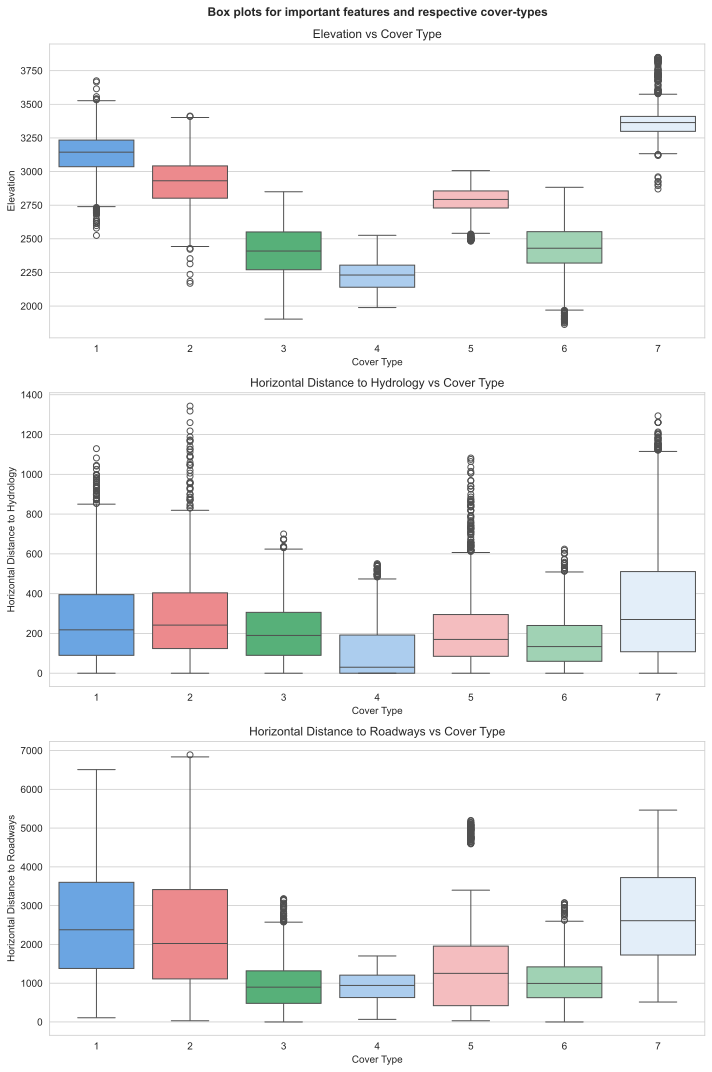

In [ ]:
# Box plots for some of the most important features

# Create box plots for the vertical distance to hydrology, horizontal distance to hydrology, and horizontal distance to roadways
fig, axes = plt.subplots(3, 1, figsize=(10, 15))

# Box plot for Vertical Distance to Hydrology
sns.boxplot(data=data, x='Cover_Type', y='Elevation', palette=PALETTE, ax=axes[0], hue='Cover_Type')
axes[0].set_title('Elevation vs Cover Type')
axes[0].set_xlabel('Cover Type')
axes[0].set_ylabel('Elevation')
axes[0].legend().set_visible(False)

# Box plot for Horizontal Distance to Hydrology
sns.boxplot(data=data, x='Cover_Type', y='Horizontal_Distance_To_Hydrology', palette=PALETTE, ax=axes[1], hue='Cover_Type')
axes[1].set_title('Horizontal Distance to Hydrology vs Cover Type')
axes[1].set_xlabel('Cover Type')
axes[1].set_ylabel('Horizontal Distance to Hydrology')
axes[1].legend().set_visible(False)

# Box plot for Horizontal Distance to Roadways
sns.boxplot(data=data, x='Cover_Type', y='Horizontal_Distance_To_Roadways', palette=PALETTE, ax=axes[2], hue='Cover_Type')
axes[2].set_title('Horizontal Distance to Roadways vs Cover Type')
axes[2].set_xlabel('Cover Type')
axes[2].set_ylabel('Horizontal Distance to Roadways')
axes[2].legend().set_visible(False)

# Set a fig title
fig.suptitle("Box plots for seleted important features and respective cover-types", fontsize = 12, fontweight='bold', y=0.99, x=0.53)

# Adjust the layout
plt.tight_layout()
plt.show()

#### **KDE distribution plot**

C:\Users\claud\AppData\Local\Temp\ipykernel_23308\1333324229.py:9: UserWarning: The palette list has more values (9) than needed (7), which may not be intended.
  sns.kdeplot(data=data,
C:\Users\claud\AppData\Local\Temp\ipykernel_23308\1333324229.py:9: UserWarning: The palette list has more values (9) than needed (7), which may not be intended.
  sns.kdeplot(data=data,
C:\Users\claud\AppData\Local\Temp\ipykernel_23308\1333324229.py:9: UserWarning: The palette list has more values (9) than needed (7), which may not be intended.
  sns.kdeplot(data=data,


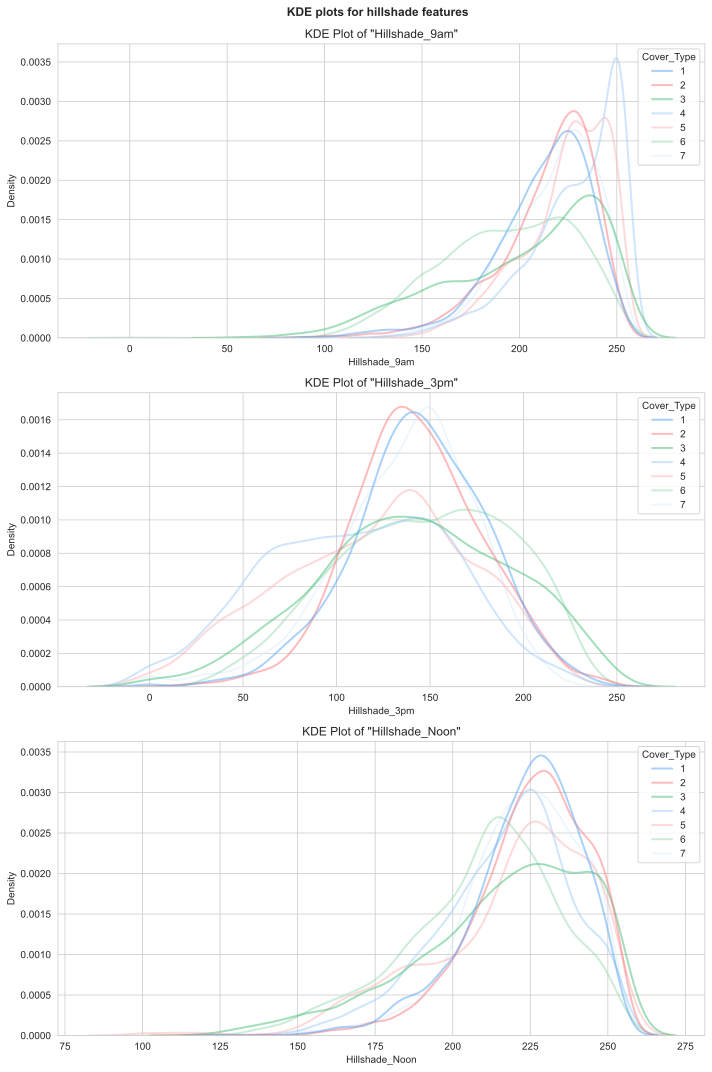

In [27]:
# KDE plots for some of the most important features

# KDE plots per covertype for the Hillshade features
features = ['Hillshade_9am', 'Hillshade_3pm', 'Hillshade_Noon']
fig, axes = plt.subplots(3, 1, figsize=(10, 15))

# Create the KDE plots for each feature
for ax, feature in zip(axes, features):
    sns.kdeplot(data=data, 
                x=feature, 
                hue='Cover_Type', 
                alpha=0.5, 
                palette=PALETTE, 
                ax=ax, 
                linewidth=2)
    ax.set_title(f'KDE Plot of "{feature}"')
    ax.set_ylabel('Density')

# Set the figure title of the figure
fig.suptitle('KDE plots for hillshade features', fontweight='bold', fontsize = 12, y=0.99, x=0.53)

plt.tight_layout()
plt.show()

#### **Mean aspect plot**

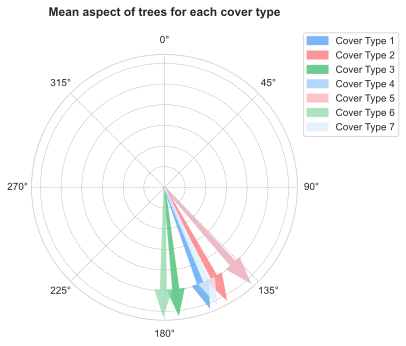

In [28]:
# Plot the mean aspect for each cover_type

# Calculate the mean aspect for each cover type
mean_aspect_per_cover_type = data.groupby('Cover_Type')['Aspect'].mean()

# Convert to radians for the polar plot
mean_aspect_rad_per_cover_type = np.deg2rad(mean_aspect_per_cover_type)

# Create the polar plot for each cover type
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
ax.set_theta_zero_location("N")  # Set North to the top
ax.set_theta_direction(-1)       # Clockwise direction

# Plot the mean values as arrows for each cover type
for idx, (cover_type, mean_aspect_rad) in enumerate(mean_aspect_rad_per_cover_type.items()):
    ax.arrow(mean_aspect_rad, 0, 0, 1, alpha=0.8, width=0.05, color=PALETTE[idx % len(PALETTE)], lw=2, label=f'Cover Type {cover_type}')

# Customize the grid
ax.set_yticklabels([])
ax.grid(True, linestyle='--', linewidth=0.5, color='gray', alpha=0.7)

# Title and legend
plt.title("Mean aspect of trees for each cover type", pad=20, fontsize=12, fontweight='bold')
plt.legend(loc='best', bbox_to_anchor=(1.4, 1.1))
plt.show()

---
## **Feature Engineering and modelling preparations**
**Section: Generating Features**  
As part of feature engineering, two additional features are generated.

These features are intended to improve model performance and are constructed using already useful features. Additionally, the distributions of the newly generated features are plotted to visualize their relationship with the cover-type.

**Section: Preparation for Modeling**  
First, the data is split into training data and the target variable.
Afterward, the data is transformed for modeling.

The data is transformed in three ways:
  - Normalized
  - Standardized
  - Normalized and standardized

Since it is not yet known which transformation will yield the best performance, different data transformations will be tested. To see the effects of the transformations, the data is also plotted.

**Section: Splitting the Data into Training and Test Sets**  
Finally, the data is prepared for modeling using a train-test split.

### **Generating Features**
#### **Generate new Hydrology-Feature**
The two hydrology features appear to be highly informative for the algorithms. Therefore, creating a new feature by combining these two variables could prove beneficial.

The goal is to engineer a new feature that represents the Euclidean distance from each data point to the nearest surface water source.

This feature is calculated as follows:

$$
\text{Euclidean\_Hydrology\_Distance} = \sqrt{\text{Horizontal\_Distance\_To\_Hydrology}^2 + \text{Vertical\_Distance\_To\_Hydrology}^2}
$$


![Hydrology Feature Sketch](assets/hydrology-sketch.png)

In [ ]:
# Copy the data to avoid changing the original data with the new features
data_ex = data.copy()

In [30]:
# Create a new feature called euclidean distance to hydrology

# Calculate the Euclidean distance to hydrology
data_ex['Euclidean_Distance_To_Hydrology'] = np.sqrt(data_ex['Horizontal_Distance_To_Hydrology']**2 + data_ex['Vertical_Distance_To_Hydrology']**2)

#### **Generate new Human_impact-Feature**
Similar to the previous step, the goal here is to create a new, more impactful feature by combining two existing features that are relevant to the algorithm.

The idea is to engineer a 'Human Impact' feature. The intention is to emphasize the effects of human presence by adding the distances to different man-made points of interest and then squaring the result.

The feature is calculated as follows:

$$
\text{Human\_Impact\_Distance} = ({\text{Horizontal\_Distance\_To\_Roadways} + \text{Horizontal\_Distance\_To\_Fire\_Points}})^2
$$

![Human Impact Feature Sketch](assets/human-impact-sketch.png)

In [31]:
# Create a new feature called human impact

# Calculate the human impact
data_ex['Human_Impact'] = (data_ex['Horizontal_Distance_To_Roadways'] + data_ex['Horizontal_Distance_To_Fire_Points'])**2

#### **Plot the newly created features**

C:\Users\claud\AppData\Local\Temp\ipykernel_23308\2017095508.py:7: UserWarning: The palette list has more values (9) than needed (7), which may not be intended.
  sns.boxplot(data=data_ex, x='Cover_Type', y='Human_Impact', palette=PALETTE, ax=axes[0], hue='Cover_Type')
C:\Users\claud\AppData\Local\Temp\ipykernel_23308\2017095508.py:14: UserWarning: The palette list has more values (9) than needed (7), which may not be intended.
  sns.boxplot(data=data_ex, x='Cover_Type', y='Euclidean_Distance_To_Hydrology', palette=PALETTE, ax=axes[1], hue='Cover_Type')


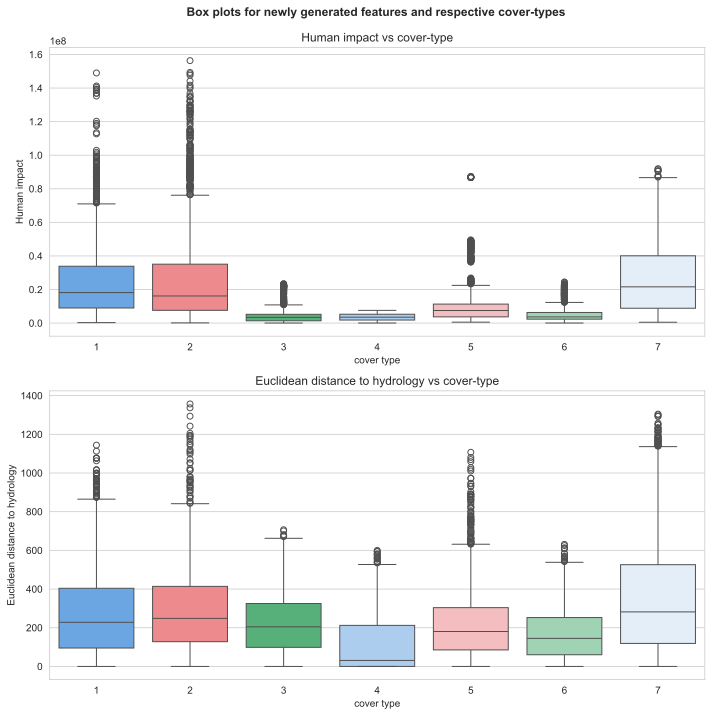

In [32]:
# Plot the above created features called human impact, euclidean distance to hydrology

# Create box plots for the human impact and euclidean distance to hydrology
fig, axes = plt.subplots(2, 1, figsize=(10, 10))

# Box plot for Human Impact
sns.boxplot(data=data_ex, x='Cover_Type', y='Human_Impact', palette=PALETTE, ax=axes[0], hue='Cover_Type')
axes[0].set_title('Human impact vs cover-type')
axes[0].set_xlabel('cover type')
axes[0].set_ylabel('Human impact')
axes[0].legend().set_visible(False)

# Box plot for Euclidean Distance to Hydrology
sns.boxplot(data=data_ex, x='Cover_Type', y='Euclidean_Distance_To_Hydrology', palette=PALETTE, ax=axes[1], hue='Cover_Type')
axes[1].set_title('Euclidean distance to hydrology vs cover-type')
axes[1].set_xlabel('cover type')
axes[1].set_ylabel('Euclidean distance to hydrology')
axes[1].legend().set_visible(False)

# Set a fig title
fig.suptitle('Box plots for newly generated features and respective cover-types ', fontweight='bold', fontsize = 12, y=0.99, x=0.53)

# Adjust the layout
plt.tight_layout()
plt.show()

---
### **Preparations for modelling**
#### **Standardizing and scaling**

In [33]:
# Splitting the data into target and features

# Splitting the data into target and features by dropping the columns 'Cover_Type' and 'Id'
X_data = data.drop(columns=['Cover_Type', 'Id'], axis = 1)
Y_data = data['Cover_Type']

# Splitting the data with the expanded features into target and features by dropping the columns 'Cover_Type' and 'Id'
X_data_ex = data_ex.drop(columns=['Cover_Type', 'Id'], axis = 1)
Y_data_ex = data_ex['Cover_Type']

In [34]:
# Using StandardScaler and normalize from scikit to process the data

# Processing the original data
# Scaling the data with the StandardScaler from sklearn
scaler = preprocessing.StandardScaler()
X_data_scaled = scaler.fit_transform(X_data)
X_data_scaled = pd.DataFrame(X_data_scaled, 
                             columns = X_data.columns)

# Normalizing the data by using the normalize function from sklearn
X_data_norm = preprocessing.normalize(X_data, norm='l2')
X_data_norm = pd.DataFrame(X_data_norm, 
                             columns = X_data.columns)

# Normalizing the scaled data with StandardScaler from Sklearn
X_data_sn = preprocessing.normalize(X_data_scaled, norm='l2')
X_data_sn = pd.DataFrame(X_data_sn, 
                             columns = X_data.columns)


# Processing the data with the expanded features
# Scaling the data with the StandardScaler from sklearn
scaler = preprocessing.StandardScaler()
X_data_scaled_ex = scaler.fit_transform(X_data_ex)
X_data_scaled_ex = pd.DataFrame(X_data_scaled_ex,
                                columns = X_data_ex.columns)

# Normalizing the data by using the normalize function from sklearn
X_data_norm_ex = preprocessing.normalize(X_data_ex, norm='l2')
X_data_norm_ex = pd.DataFrame(X_data_norm_ex,
                              columns = X_data_ex.columns)

# Normalizing the scaled data with StandardScaler from Sklearn
X_data_sn_ex = preprocessing.normalize(X_data_scaled_ex, norm='l2')
X_data_sn_ex = pd.DataFrame(X_data_sn_ex,
                             columns = X_data_ex.columns)

---
#### **Plot the scaled data**
For a better understanding of how the data gets scaled.

C:\Users\claud\AppData\Local\Temp\ipykernel_23308\802572156.py:25: UserWarning: The palette list has more values (9) than needed (3), which may not be intended.
  sns.boxplot(data=elevation_data_melted, x='Dataset', y='Elevation', ax=ax2, palette=PALETTE, hue='Dataset')


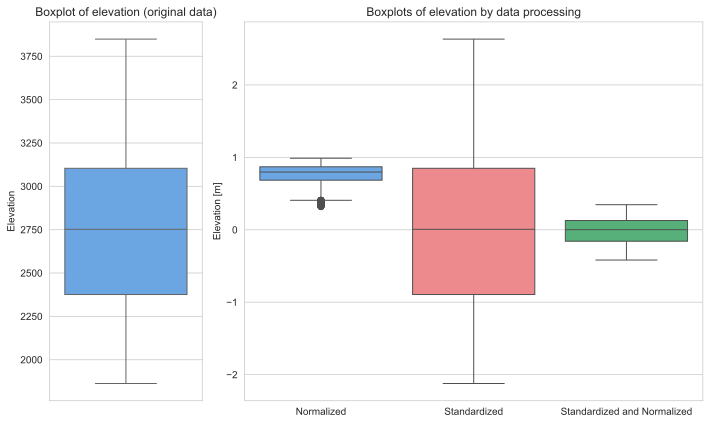

In [35]:
# Plot the Elevation data in boxplots to see the difference

# Combine the data into a single DataFrame for plotting
elevation_data = pd.DataFrame({
    'Original': X_data['Elevation'],
    'Normalized': X_data_norm['Elevation'],
    'Standardized': X_data_scaled['Elevation'],
    'Standardized and Normalized': X_data_sn['Elevation']
})

# Melt the DataFrame to long format
elevation_data_melted = elevation_data.melt(var_name='Dataset', value_name='Elevation')

# Create a figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6), gridspec_kw={'width_ratios': [1, 3]})

# Plot the boxplot for the original data on the first subplot
sns.boxplot(data=X_data['Elevation'], ax=ax1)
ax1.set_title('Boxplot of elevation (original data)')
ax1.set_ylabel('Elevation')

# Remove the original elevation data from the DataFrame
elevation_data_melted = elevation_data_melted[elevation_data_melted['Dataset'] != 'Original']
# Plot the boxplots for the normalized, standardized, and standardized & normalized data on the second subplot
sns.boxplot(data=elevation_data_melted, x='Dataset', y='Elevation', ax=ax2, palette=PALETTE, hue='Dataset')
ax2.set_title('Boxplots of elevation by data processing')
ax2.set_xlabel('')
ax2.set_ylabel('Elevation [m]')

# Adjust layout
plt.tight_layout()
plt.show()

In [36]:
# Plot the Horizontal_Distance_To_Hydrology and Vertical_Distance_To_Hydrology data to see the difference

# Sample 20% of the data points (just so im able to see the scatterplot)
sampled_X_data = X_data.sample(frac=0.2, random_state=42)
sampled_X_data_norm = X_data_norm.sample(frac=0.2, random_state=42)
sampled_X_data_sn = X_data_sn.sample(frac=0.2, random_state=42)
sampled_X_data_scaled = X_data_scaled.sample(frac=0.2, random_state=42)

# Create a figure with four subplots
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Set the figure title of the figure
fig.suptitle('distance_to_hydrology features by preprocessing method with 20% sampled data and mean values as red dashed lines', fontsize = 12, y = 1.0, fontweight='bold')   

# Plot for sampled_X_data (original data)
sns.scatterplot(ax=axes[0, 0], x=sampled_X_data['Horizontal_Distance_To_Hydrology'], y=sampled_X_data['Vertical_Distance_To_Hydrology'], alpha=0.5)
axes[0, 0].set_title('Original Data')
axes[0, 0].set_xlabel('Horizontal Distance to Hydrology')
axes[0, 0].set_ylabel('Vertical Distance to Hydrology')
axes[0, 0].axvline(sampled_X_data['Horizontal_Distance_To_Hydrology'].mean(), color='r', linestyle='--')
axes[0, 0].axhline(sampled_X_data['Vertical_Distance_To_Hydrology'].mean(), color='r', linestyle='--')

# Plot for sampled_X_data_norm
sns.scatterplot(ax=axes[0, 1], x=sampled_X_data_norm['Horizontal_Distance_To_Hydrology'], y=sampled_X_data_norm['Vertical_Distance_To_Hydrology'], alpha=0.5)
axes[0, 1].set_title('Normalized Data')
axes[0, 1].set_xlabel('Horizontal Distance to Hydrology')
axes[0, 1].set_ylabel('Vertical Distance to Hydrology')
axes[0, 1].axvline(sampled_X_data_norm['Horizontal_Distance_To_Hydrology'].mean(), color='r', linestyle='--')
axes[0, 1].axhline(sampled_X_data_norm['Vertical_Distance_To_Hydrology'].mean(), color='r', linestyle='--')

# Plot for sampled_X_data_scaled
sns.scatterplot(ax=axes[1, 0], x=sampled_X_data_scaled['Horizontal_Distance_To_Hydrology'], y=sampled_X_data_scaled['Vertical_Distance_To_Hydrology'], alpha=0.5)
axes[1, 0].set_title('Standardized Data')
axes[1, 0].set_xlabel('Horizontal Distance to Hydrology')
axes[1, 0].set_ylabel('Vertical Distance to Hydrology')
axes[1, 0].axvline(sampled_X_data_scaled['Horizontal_Distance_To_Hydrology'].mean(), color='r', linestyle='--')
axes[1, 0].axhline(sampled_X_data_scaled['Vertical_Distance_To_Hydrology'].mean(), color='r', linestyle='--')

# Plot for sampled_X_data_sn
sns.scatterplot(ax=axes[1, 1], x=sampled_X_data_sn['Horizontal_Distance_To_Hydrology'], y=sampled_X_data_sn['Vertical_Distance_To_Hydrology'], alpha=0.5)
axes[1, 1].set_title('Standardized and Normalized Data')
axes[1, 1].set_xlabel('Horizontal Distance to Hydrology')
axes[1, 1].set_ylabel('Vertical Distance to Hydrology')
axes[1, 1].axvline(sampled_X_data_sn['Horizontal_Distance_To_Hydrology'].mean(), color='r', linestyle='--')
axes[1, 1].axhline(sampled_X_data_sn['Vertical_Distance_To_Hydrology'].mean(), color='r', linestyle='--')

plt.tight_layout()
plt.show()

---
#### **Splitting data into training and test sets**
Split the data into train and test split with 15% remaining in the test set.

In [37]:
# Set the split percentage
perc = 0.15

# Splitting Data into test and training set for normal, scaled and normalized data from the original data
# Split normal data
X_train, X_test, Y_train, Y_test = train_test_split(X_data, Y_data, test_size=perc, random_state=420)

# Split scaled data
X_train_scaled, X_test_scaled, Y_train, Y_test = train_test_split(X_data_scaled, Y_data, test_size=perc, random_state=420) 

# Split normalized data
X_train_norm, X_test_norm, Y_train, Y_test = train_test_split(X_data_norm, Y_data, test_size=perc, random_state=420)

# Split scaled and normalized data
X_train_sn, X_test_sn, Y_train, Y_test = train_test_split(X_data_sn, Y_data, test_size=perc, random_state=420)

# Splitting Data into test and training set for the expanded feature set
# Split normal data
X_train_ex, X_test_ex, Y_train, Y_test = train_test_split(X_data_ex, Y_data, test_size=perc, random_state=420)

# Split scaled data
X_train_scaled_ex, X_test_scaled_ex, Y_train, Y_test = train_test_split(X_data_scaled_ex, Y_data, test_size=perc, random_state=420)

# Split normalized data
X_train_norm_ex, X_test_norm_ex, Y_train, Y_test = train_test_split(X_data_norm_ex, Y_data, test_size=perc, random_state=420)

# Split scaled and normalized data
X_train_sn_ex, X_test_sn_ex, Y_train, Y_test = train_test_split(X_data_sn_ex, Y_data, test_size=perc, random_state=420)

---

## **Modelling, Training and Validating**
Initially, various algorithms suitable for the given problem are analyzed. The goal is to establish a baseline for model performance, with the results recorded in the *pretesting_results.csv* file.

The best-performing algorithms from the analysis are further refined to achieve even better results.   
In addition to the algorithms with good results, I will also train a few others that I have selected out of personal interest.

Specifically, the following algorithms are further analysed:
- LogisticRegression
- K-nearest neighbor
- RandomForestClassifier
- HistGradientBoostingClassifier



The deeper analysis is conducted as follows:
- **Baseline Model Calculation:**
The models are tested again to analyze CV scores, accuracy, and the confusion matrix. A ROC curve is not considered here as it does not provide insight into how the model assigns categories (correctly or incorrectly).
- **Extended Model Calculation:**
The models are re-evaluated either with the newly generated features or with only the most important features, hopefully to improve performance.
- **Detailed Investigation:**
Finally, a more in-depth analysis is performed, such as hyperparameter optimization or additional investigations based on specific questions and personal interest.
- **Final Model Calculation:**
Lastly, the model is calculated again using insights from the Detailed Investigation. Ideally, the model should now perform better than in the Baseline Model Calculation and the Extended Model Calculation.

**Note:**  
It is important to note that the possibilities for tuning and testing these algorithms are nearly endless. The primary goal of this section was to experiment with different techniques and deepen my understanding of their potential. As such, the following analysis represents a snapshot of that learning process, not a definitive solution.

### **Baseline algorithm analysis**
Creating and testing various algorithms that serve as a baseline for further processing. The results can be seen in the matrix illustration.

In [ ]:
# Test multiple models with cross-validation to see which one performs best as a baseline

# Creating a list of certain possible ML-models
models = [LogisticRegression(n_jobs=-1), 
          sklearn.neighbors.KNeighborsClassifier(),
          svm.SVC(), 
          RandomForestClassifier(n_jobs=-1),
          HistGradientBoostingClassifier(),
          GradientBoostingClassifier(),
          AdaBoostClassifier(algorithm='SAMME'),          
          ]

# Creating a list of the model names
model_names = ['Logistic Regression',
               'K-Nearest Neighbour',
               'SVC', 
               'Random-Forest',
               'HistGradientBoostingClassifier',
               'GradientBoostingClassifier', 
                'AdaBoostClassifier'               
               ]

# Creating an empty list to store the results for each model
results_original = []
results_scaled = []
results_normalized = []
results_scaled_normalized = []

# Looping through all models and storing the results in the results list
for model, model_name in zip(models, model_names):
    # Cross-validation with original data
    scores_original = cross_val_score(model, X_train, Y_train, cv=3, scoring='accuracy', n_jobs=-1)
    accuracy_original = scores_original.mean()
    results_original.append([model_name, accuracy_original])

    # Cross-validation with scaled data
    scores_scaled = cross_val_score(model, X_train_scaled, Y_train, cv=3, scoring='accuracy', n_jobs=-1)
    accuracy_scaled = scores_scaled.mean()
    results_scaled.append([model_name, accuracy_scaled])
    
    # Cross-validation with normalized data
    scores_norm = cross_val_score(model, X_train_norm, Y_train, cv=3, scoring='accuracy', n_jobs=-1)
    accuracy_norm = scores_norm.mean()
    results_normalized.append([model_name, accuracy_norm])
    
    # Cross-validation with standardized and normalized data
    scores_sn = cross_val_score(model, X_train_sn, Y_train, cv=3, scoring='accuracy', n_jobs=-1)
    accuracy_sn = scores_sn.mean()
    results_scaled_normalized.append([model_name, accuracy_sn])

    print(f"Model: {model_name} finished")

# Convert results to DataFrame
pre_results_scaled_df = pd.DataFrame(results_scaled, columns=['Model', 'Accuracy (Scaled)'])
pre_results_normalized_df = pd.DataFrame(results_normalized, columns=['Model', 'Accuracy (Normalized)'])
pre_results_original_df = pd.DataFrame(results_original, columns=['Model', 'Accuracy (Original)'])
pre_results_scaled_normalized_df = pd.DataFrame(results_scaled_normalized, columns=['Model', 'Accuracy (Scaled & Normalized)'])

# Merge results into a single DataFrame
prestesting_results_df = pre_results_scaled_df.merge(pre_results_normalized_df, on='Model').merge(pre_results_original_df, on='Model').merge(pre_results_scaled_normalized_df, on='Model')

# Save the results to a CSV file
prestesting_results_df.to_csv('results/pretesting_results.csv')

Model: Logistic Regression abgeschlossen
Model: K-Nearest Neighbour abgeschlossen
Model: SVC abgeschlossen
Model: Random Forest abgeschlossen
Model: HistGradientBoostingClassifier abgeschlossen
Model: GradientBoostingClassifier abgeschlossen
Model: AdaBoostClassifier abgeschlossen


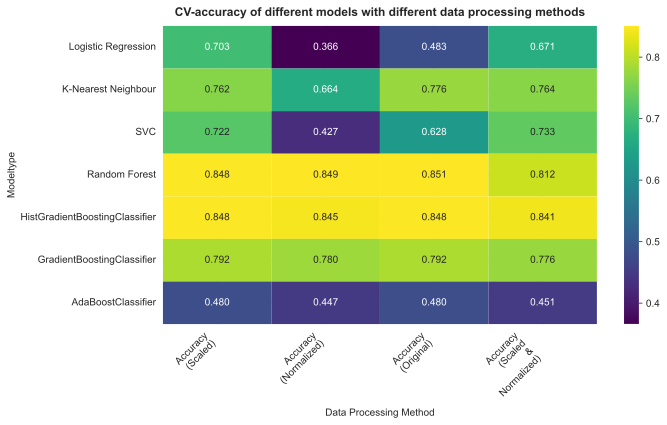

In [7]:
# Plot the results as a matrix

# Load the pretesting data
pretesting_results = pd.read_csv('results/pretesting_results.csv')

# Drop the first column
pretesting_results = pretesting_results.drop(pretesting_results.columns[0], axis=1)

# Plot the results as a matrix
# Create a heatmap of the results
plt.figure(figsize=(10, 6))
ax = sns.heatmap(pretesting_results.set_index('Model'), annot=True, cmap='viridis', fmt='.3f')

# Set the title and labels
plt.title("CV-accuracy of different models with different data processing methods", fontdict={'fontsize': 12, 'fontweight': 'bold'}, pad=10)
plt.xlabel("Data Processing Method", labelpad=10)
plt.ylabel("Modeltype")

# Wrap the x-tick labels
xticks_labels = ['\n'.join(label.split()) for label in pretesting_results.columns[1:]]
ax.set_xticklabels(xticks_labels, rotation=45, ha='right')

# Adjust the layout
plt.tight_layout()
plt.show()

---
### **Logistical regression**

##### **Logistical regression baseline with standardized data**
The best model from the baseline analysis.

In [10]:
# Set a logistic regression models
log_reg = sklearn.linear_model.LogisticRegression(n_jobs=-1)

##############
Cross-Validation Accuracies:  [0.70985061 0.69070962 0.70728291]
Mean CV Accuracy: 0.70
Test Accuracy: 0.70
##############


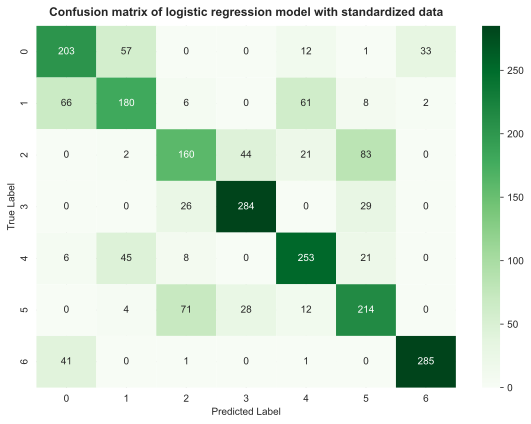

In [74]:
# Logistical regression model on the standardized data

# Perform 3-fold cross-validation
kf = KFold(n_splits=3, shuffle=True, random_state=420)
cv_scores = cross_val_score(log_reg, X_train_scaled, Y_train, cv=kf, scoring='accuracy', n_jobs=-1)

# Train the model on the entire training set
log_reg.fit(X_train_scaled, Y_train)

# Evaluate on the test set
test_accuracy = log_reg.score(X_test_scaled, Y_test)

# Output CV and test results
print("##############")
print("Cross-Validation Accuracies: ", cv_scores)
print("Mean CV Accuracy: %.2f" % cv_scores.mean())
print("Test Accuracy: %.2f" % test_accuracy)
print("##############")

# Predict the test set
Y_pred_log = log_reg.predict(X_test_scaled)

# Create the confusion matrix
confusion_matrix = sklearn.metrics.confusion_matrix(Y_test, Y_pred_log)

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix, annot=True, fmt='d', cmap='Greens')

# Set the title and labels
plt.title("Confusion matrix of logistic regression model with standardized data", fontdict={'fontsize': 12, 'fontweight': 'bold'}, pad=10)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

# Adjust the layout
plt.tight_layout()

# Show the plot
plt.show()

#### **Logistical regression with standardized features and newly generated features**
Test the model with the newly generated and standardised features to see if it improves.

##############
Cross-Validation Accuracies:  [0.7124183  0.69467787 0.71218487]
Mean CV Accuracy: 0.71
Test Accuracy: 0.70
##############


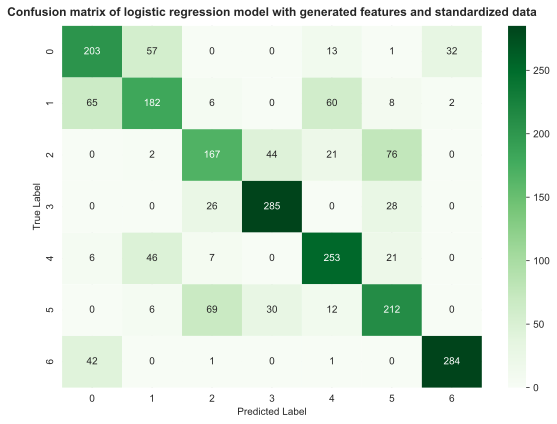

In [77]:
# Perform 3-fold cross-validation
kf = KFold(n_splits=3, shuffle=True, random_state=420)
cv_scores = cross_val_score(log_reg, X_train_scaled_ex, Y_train, cv=kf, scoring='accuracy', n_jobs=-1)

# Train the model on the entire training set
log_reg.fit(X_train_scaled_ex, Y_train)

# Evaluate on the test set
test_accuracy = log_reg.score(X_test_scaled_ex, Y_test)

# Output CV and test results
print("##############")
print("Cross-Validation Accuracies: ", cv_scores)
print("Mean CV Accuracy: %.2f" % cv_scores.mean())
print("Test Accuracy: %.2f" % test_accuracy)
print("##############")

# Predict the test set
Y_pred_log = log_reg.predict(X_test_scaled_ex)

# Create the confusion matrix
confusion_matrix = sklearn.metrics.confusion_matrix(Y_test, Y_pred_log)

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix, annot=True, fmt='d', cmap='Greens')

# Set the title and labels
plt.title("Confusion matrix of logistic regression model with generated features and standardized data", fontdict={'fontsize': 12, 'fontweight': 'bold'}, pad=10)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

# Adjust the layout
plt.tight_layout()

# Show the plot
plt.show()

#### **Logistical regression behaviour based on data amount**
As a further analysis, the behaviour of the logistic regression algorithm is tested on a varying amount of data for training.

It can be seen that the algorithm quickly converges to maximum accuracy. The amount of data required to achieve maximum accuracy is therefore quickly reached.

In [11]:
# Logistical regression model on different amounts of data

# Create empty lists and the initial starting fraction (0.1% in this case)
accuracy_sampled = []
accuracy_sampled_cv = []
data_perc = []
n_samples = []
frac_p = 0.001

# Create a loop which increases the amount of training Data by 0.1% each loop, and then calculate the accuracy
while frac_p <= 1:

    # Sample a percentage of data out of the data df
    sampled_data = data.sample(frac=frac_p)

    # Drop ID and Cover_Type column (which is the y variable)
    X_sampled = sampled_data.drop(columns=['Cover_Type', 'Id'], axis=1)
    Y_sampled = sampled_data['Cover_Type']

    # Scaling the data with the StandardScaler from sklearn
    scaler = preprocessing.StandardScaler()
    X_sampled_scaled = scaler.fit_transform(X_sampled)
    X_sampled_scaled = pd.DataFrame(X_sampled_scaled, 
                                    columns = X_sampled.columns)

    # Use the data in train_test_split to create splits
    X_train_sampled, X_test_sampled, Y_train_sampled, Y_test_sampled = train_test_split(X_sampled_scaled, Y_sampled, test_size=0.2)
     
    # Perform 3-fold cross-validation
    kf = KFold(n_splits=3, shuffle=True, random_state=420)
    cv_scores = cross_val_score(log_reg, X_train_sampled, Y_train_sampled, cv=kf, scoring='accuracy', n_jobs=-1)

    # Fitting the model
    log_reg.fit(X_train_sampled, Y_train_sampled)

    # Predicting the test set
    Y_pred_sampled = log_reg.predict(X_test_sampled)

    # Evaluate on the test set
    test_accuracy_sampled = log_reg.score(X_test_sampled, Y_test_sampled)

    # Appending the accuracy and data percent to the lists
    accuracy_sampled.append(test_accuracy_sampled)
    accuracy_sampled_cv.append(cv_scores.mean())
    data_perc.append(frac_p)
    n_samples.append(len(Y_sampled))

    # For every iteration increase the number of frac_p based on the current value
    if frac_p < 0.15:
        frac_p = frac_p + 0.001
    else: 
        frac_p = frac_p + 0.025

# Create a DataFrame with the results
sampled_results = pd.DataFrame({'data_perc': data_perc, 'accuracy_samp': accuracy_sampled,'accuracy_samp_cv':accuracy_sampled_cv, 'n_samples': n_samples})

# Save the results to a CSV file
sampled_results.to_csv('results/log-reg_sampling_results.csv')

C:\Users\claud\AppData\Local\Temp\ipykernel_23308\3719015458.py:14: RankWarning: Polyfit may be poorly conditioned
  p = np.poly1d(np.polyfit(data_log["data_perc"], data_log["accuracy_samp"], len(data_perc) - 1))
C:\Users\claud\AppData\Local\Temp\ipykernel_23308\3719015458.py:22: RankWarning: Polyfit may be poorly conditioned
  p_cv = np.poly1d(np.polyfit(data_log["data_perc"], data_log["accuracy_samp_cv"], len(data_perc) - 1))


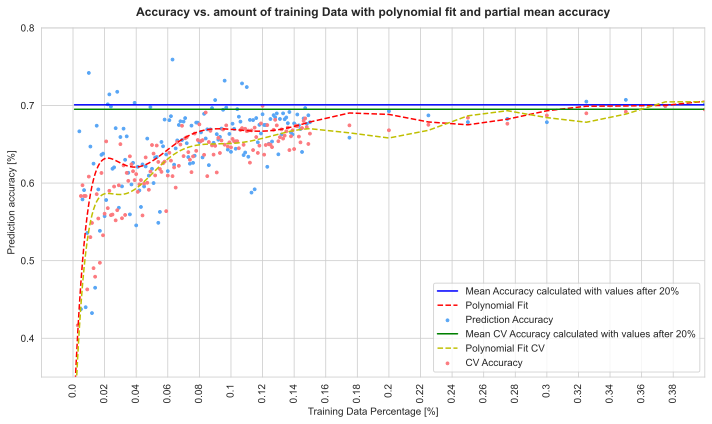

In [12]:
# Plot the data amount vs. accuracy

# Load the data
data_log = pd.read_csv('results/log-reg_sampling_results.csv')

# Create a figure
fig, ax = plt.subplots(figsize=(10, 6))

# Create a data subset with all values after the 20% mark
data_log_subset = data_log[data_log["data_perc"] > 0.2]

# Polynomial fit for the accuracy_sampled data
# Create a polynomial fit for the data
p = np.poly1d(np.polyfit(data_log["data_perc"], data_log["accuracy_samp"], len(data_perc) - 1))
# Calculate the mean accuracy of the data subset
mean_accuracy = np.mean(data_log_subset["accuracy_samp"])
# Create a mean line for the plot
mean_line = np.ones(len(data_perc)) * mean_accuracy

# Polynomial fit for the accuracy_sampled_cv data
# Create a polynomial fit for the accuracy_sampled_cv data
p_cv = np.poly1d(np.polyfit(data_log["data_perc"], data_log["accuracy_samp_cv"], len(data_perc) - 1))
# Calculate the mean accuracy of the data subset for accuracy_sampled_cv
mean_accuracy_cv = np.mean(data_log_subset["accuracy_samp_cv"])
# Create a mean line for the accuracy_sampled_cv plot
mean_line_cv = np.ones(len(data_perc)) * mean_accuracy_cv

# Plot our accuracy_sampled data gathered from above with the best fit line and mean calculated after 20%
ax.plot(data_log['data_perc'], mean_line, "b", label='Mean Accuracy calculated with values after 20%')
ax.plot(data_log['data_perc'], p(data_log['data_perc']), "r--", label='Polynomial Fit')
ax.scatter(data_log['data_perc'], data_log['accuracy_samp'], label='Prediction Accuracy', s=8)

# Plot our accuracy_sampled_cv data gathered from above with the best fit line and mean calculated after 20%
ax.plot(data_log['data_perc'], mean_line_cv, "g", label='Mean CV Accuracy calculated with values after 20%')
ax.plot(data_log['data_perc'], p_cv(data_log['data_perc']), "y--", label='Polynomial Fit CV')
ax.scatter(data_log['data_perc'], data_log['accuracy_samp_cv'], label='CV Accuracy', s=8)

# Set the title and labels and blabla
ax.set_title('Accuracy vs. amount of training Data with polynomial fit and partial mean accuracy', fontweight='bold', pad=12, fontsize=12)        
ax.set_xlabel('Training Data Percentage [%]')
ax.set_ylabel('Prediction accuracy [%]')
ax.set_xlim(-0.02, 0.4)
ax.set_ylim(0.35, 0.8)
ax.grid(True)
ax.set_xticks(np.arange(0, 0.4, step=0.02))
ax.set_xticklabels(np.arange(0, 0.4, step=0.02), rotation=90)
ax.legend()

# Adjust the position of the legend to the right lower corner
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

---
### **k-nearest neighbour**

#### **k-nearest neighbor baseline with original data**
The best model from the baseline analysis.

In [85]:
# Set a k-nearest neighbors model
knn = sklearn.neighbors.KNeighborsClassifier(n_neighbors=5)

##############
Cross-Validation Accuracies:  [0.77637722 0.77917834 0.77334267]
Mean CV Accuracy: 0.78
Test Accuracy: 0.81
##############


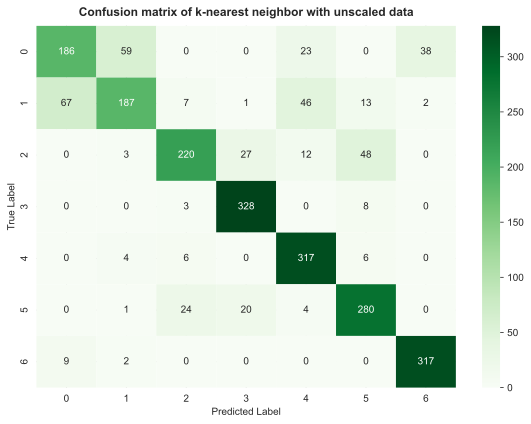

In [86]:
# Try a k nearest neighbors model with all features and original data

# Perform 3-fold cross-validation
kf = KFold(n_splits=3, shuffle=True, random_state=420)
cv_scores = cross_val_score(knn, X_train, Y_train, cv=kf, scoring='accuracy', n_jobs=-1)

# Train the model on the entire training set
knn.fit(X_train, Y_train)

# Predict the test set
Y_pred_kn = knn.predict(X_test)

# Output CV and test results
print("##############")
print("Cross-Validation Accuracies: ", cv_scores)
print("Mean CV Accuracy: %.2f" % cv_scores.mean())
print("Test Accuracy: %.2f" % accuracy_score(Y_pred_kn, Y_test))
print("##############")

# Create the confusion matrix
confusion_matrix = sklearn.metrics.confusion_matrix(Y_test, Y_pred_kn)

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix, annot=True, fmt='d', cmap='Greens')

# Set the title and labels
plt.title("Confusion matrix of k-nearest neighbor with unscaled data", fontdict={'fontsize': 12, 'fontweight': 'bold'}, pad=10)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

# Adjust the layout
plt.tight_layout()

# Show the plot
plt.show()

#### **k-nearest neighbor "n_neighbors" hyperparameteranalysis with most important features**
As a further analysis, the best setting for the `n_neighbors` parameter should be found. Only the most important features that were defined in an earlier section are used here.

In [38]:
# Try a k-nearest neighbour with the most important features

# Select the columns with the most important features and keep the 'Cover_Type' column
data_top_features = data[combined_top_features['Feature'].tolist() + ['Cover_Type']]

# Split the data into target and features by dropping the columns 'Cover_Type' and 'Id'
X_data_top = data_top_features.drop(columns=['Cover_Type'], axis=1)
Y_data_top = data_top_features['Cover_Type']

# Split the data into training and test sets
X_train_top, X_test_top, Y_train_top, Y_test_top = train_test_split(X_data_top, Y_data_top, test_size=0.2, random_state=420)

# Accuracy list
cross_accuracy = []
accuracy = []

for n in range(1, 21):
    # Set a k-nearest neighbors model
    knn = sklearn.neighbors.KNeighborsClassifier(n_neighbors=n)

    # Append the accuracy to the list with 3-fold cross-validation
    kf = KFold(n_splits=3, shuffle=True, random_state=420)
    cross_accuracy.append(cross_val_score(knn, 
                                    X_train_top, 
                                    Y_train_top, 
                                    cv=kf, 
                                    scoring="accuracy", 
                                    n_jobs = -1).mean())
        
    # Train the model on the entire training set
    knn.fit(X_train_top, Y_train_top)

    # Predict the test set
    Y_pred = knn.predict(X_test_top)

    accuracy.append(accuracy_score(Y_pred, Y_test_top))

    # Number of iterations
    print("Repeat {}/{}".format(n, 20))

# Save the results to a CSV file
knn_hyperparameter_results = pd.DataFrame({'n_neighbors': range(1, 21), 'cross_val_accuracy': cross_accuracy, 'test_accuracy': accuracy})
knn_hyperparameter_results.to_csv('results/knn_hyperparameter_results.csv')

Repeat 1/20
Repeat 2/20
Repeat 3/20
Repeat 4/20
Repeat 5/20
Repeat 6/20
Repeat 7/20
Repeat 8/20
Repeat 9/20
Repeat 10/20
Repeat 11/20
Repeat 12/20
Repeat 13/20
Repeat 14/20
Repeat 15/20
Repeat 16/20
Repeat 17/20
Repeat 18/20
Repeat 19/20
Repeat 20/20


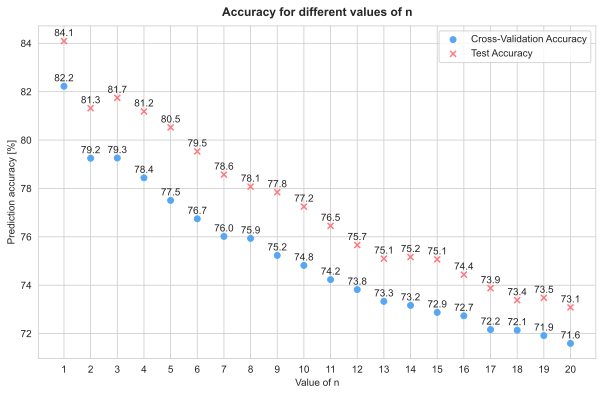

In [39]:
# Plot the accuracy for different values of n

# Load the data
knn_hyperparameter_results = pd.read_csv('results/knn_hyperparameter_results.csv')

# Plot the accuracy for different values of n
plt.figure(figsize=(10, 6))
plt.scatter(range(1, 21), [acc * 100 for acc in cross_accuracy], marker='o', label='Cross-Validation Accuracy')
plt.scatter(range(1, 21), [acc * 100 for acc in accuracy], marker='x', label='Test Accuracy')

# Set title and labels
plt.title('Accuracy for different values of n', fontdict={'fontsize': 12, 'fontweight': 'bold'}, pad=10)
plt.xlabel('Value of n')
plt.ylabel('Prediction accuracy [%]')

# Set xticks
plt.xticks(range(1, 21))

# Set lettering next to data points for test accuracy
for i, txt in enumerate(accuracy):
    plt.annotate(f'{accuracy[i] * 100:.1f}', (i + 1, accuracy[i] * 100), textcoords="offset points", xytext=(0, 5), ha='center')
    plt.annotate(f'{cross_accuracy[i] * 100:.1f}', (i + 1, cross_accuracy[i] * 100), textcoords="offset points", xytext=(0, 5), ha='center')

# Set grid
plt.grid(True)

# Add legend
plt.legend()
plt.show()

#### **k-nearest neighbor with best hyperparameters**
Test the model with the best hyperparameters to hopefully form the best k-nearest neighbour model.

##############
Cross-Validation Accuracies:  [0.81862745 0.83403361 0.81932773]
Mean CV Accuracy: 0.82
Test Accuracy: 0.85
##############


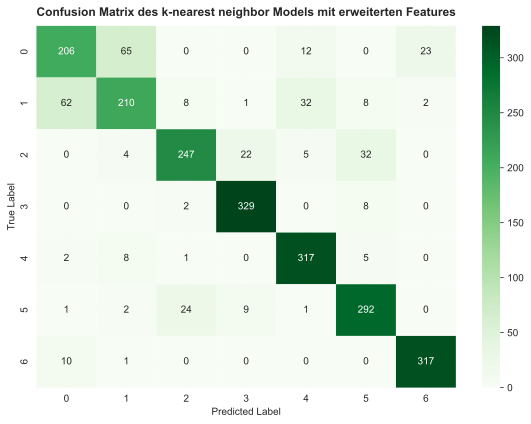

In [184]:
# Set a k-nearest neighbors model
knn = sklearn.neighbors.KNeighborsClassifier(n_neighbors=1)

# Perform 3-fold cross-validation
kf = KFold(n_splits=3, shuffle=True, random_state=420)
cv_scores = cross_val_score(knn, X_train, Y_train, cv=kf, scoring='accuracy', n_jobs=-1)

# Train the model on the entire training set
knn.fit(X_train, Y_train)

# Predict the test set
Y_pred_kn = knn.predict(X_test)

# Output CV and test results
print("##############")
print("Cross-Validation Accuracies: ", cv_scores)
print("Mean CV Accuracy: %.2f" % cv_scores.mean())
print("Test Accuracy: %.2f" % accuracy_score(Y_pred_kn, Y_test))
print("##############")

# Create the confusion matrix
confusion_matrix = sklearn.metrics.confusion_matrix(Y_test, Y_pred_kn)
# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix, annot=True, fmt='d', cmap='Greens')
# Set the title and labels
plt.title("Confusion Matrix des k-nearest neighbor Models mit erweiterten Features", fontdict={'fontsize': 12, 'fontweight': 'bold'}, pad=10)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
# Adjust the layout
plt.tight_layout()
# Show the plot
plt.show()

---
### **Random-Forest**

#### **Random-Forest baseline mit original data**
The best model from the baseline analysis.

In [ ]:
# Set a Random-Forest classifier
rf_clf = RandomForestClassifier(random_state=420)

##############
Cross-Validation Accuracies:  [0.85218254 0.85367063 0.84176587]
Mean CV Accuracy: 0.85
Test Accuracy: 0.84
##############


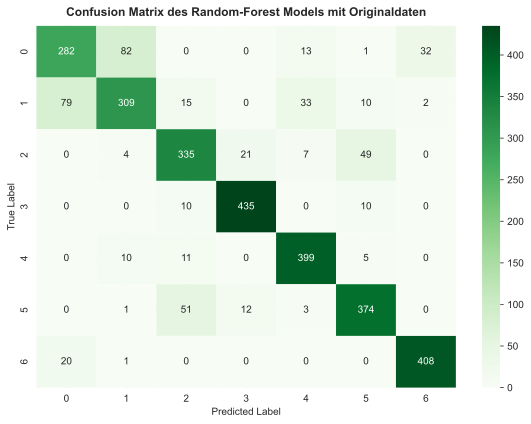

In [ ]:
# First we try a Random-Forest on the original data as baseline

# Perform 3-fold cross-validation
kf = KFold(n_splits=3, shuffle=True, random_state=420)
cv_scores = cross_val_score(rf_clf, X_train, Y_train, cv=kf, scoring='accuracy', n_jobs=-1)

# Train the model on the entire training set
rf_clf.fit(X_train, Y_train)

# Predict the test set
Y_pred_rf = rf_clf.predict(X_test)

# Output CV and test results
print("##############")
print("Cross-Validation Accuracies: ", cv_scores)
print("Mean CV Accuracy: %.2f" % cv_scores.mean())
print("Test Accuracy: %.2f" % accuracy_score(Y_pred_rf, Y_test))
print("##############")

# Create the confusion matrix
confusion_matrix = sklearn.metrics.confusion_matrix(Y_test, Y_pred_rf)
# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix, annot=True, fmt='d', cmap='Greens')
# Set the title and labels
plt.title("Confusion Matrix des Random-Forest Models mit Originaldaten", fontdict={'fontsize': 12, 'fontweight': 'bold'}, pad=10)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
# Adjust the layout
plt.tight_layout()
# Show the plot
plt.show()

#### **Random-Forest with newly generated features**
Test the model with the newly generated features to see if it improves.

##############
Cross-Validation Accuracies:  [0.86157796 0.85434174 0.86157796]
Mean CV Accuracy: 0.86
Test Accuracy: 0.86
##############


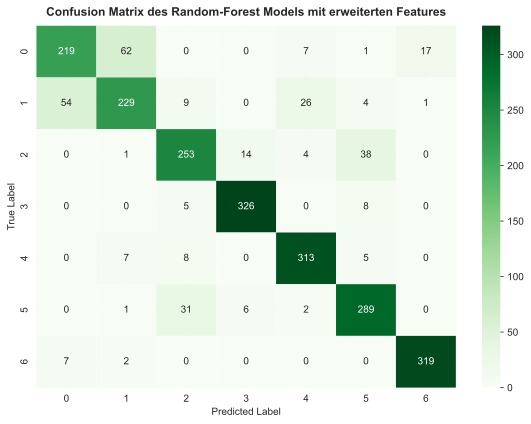

In [ ]:
# Second we try a Random-Forest on with expanded features

# Perform 3-fold cross-validation
kf = KFold(n_splits=3, shuffle=True, random_state=420)
cv_scores = cross_val_score(rf_clf, X_train_ex, Y_train, cv=kf, scoring='accuracy', n_jobs=-1)

# Train the model on the entire training set
rf_clf.fit(X_train_ex, Y_train)

# Predict the test set
Y_pred_rf = rf_clf.predict(X_test_ex)

# Output CV and test results
print("##############")
print("Cross-Validation Accuracies: ", cv_scores)
print("Mean CV Accuracy: %.2f" % cv_scores.mean())
print("Test Accuracy: %.2f" % accuracy_score(Y_pred_rf, Y_test))
print("##############")

# Create the confusion matrix
confusion_matrix = sklearn.metrics.confusion_matrix(Y_test, Y_pred_rf)
# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix, annot=True, fmt='d', cmap='Greens')
# Set the title and labels
plt.title("Confusion Matrix des Random-Forest Models mit erweiterten Features", fontdict={'fontsize': 12, 'fontweight': 'bold'}, pad=10)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
# Adjust the layout
plt.tight_layout()
# Show the plot
plt.show()

#### **Random-Forest hyperparameteranalysis with Optuna**
Optuna is used to perform a hyperparameter analysis. It is similar to SciKit-Optimize, but also offers a nice dashboard for parameter search. 

To view the dashboard, download the Optuna Dashboard extension (in the extension tab of vs-code) → right-click on the `db.sqlite3` file → click on *open in Optuna Dashboard* at the very bottom.

In [ ]:
# Using Optuna to find the best hyperparameters for Random-Forest Clasifier
# Optuna-Objective-function
def objective(trial):
    # Define the hyperparameter search space
    n_estimators = trial.suggest_int("n_estimators", 10, 200, log=True)
    max_leaf_nodes = trial.suggest_int("max_leaf_nodes", 15, 200, log=True)
    max_depth = trial.suggest_int("max_depth", 1, 200, log=True)
    min_samples_leaf = trial.suggest_int("min_samples_leaf", 1, 30)
    max_features = trial.suggest_int("max_features", 1, X_train_ex.shape[1])

    
    # HistGradientBoostingClassifier
    clf = RandomForestClassifier(
        n_estimators = n_estimators,
        max_leaf_nodes=max_leaf_nodes,
        max_depth=max_depth,
        min_samples_leaf=min_samples_leaf,
        max_features=max_features,

        random_state=420, # for reproducibility
    )
    
    # Cross-Validation-Score
    score = cross_val_score(clf, X_train_ex, Y_train, cv=3, scoring="accuracy", n_jobs = -1)
    return score.mean()

try:
    optuna.study.delete_study(study_name="RandomForest_optuna", storage="sqlite:///db.sqlite3")
except:
    pass

# Create an Optuna study
study = optuna.create_study(direction="maximize", 
                            storage = "sqlite:///db.sqlite3",
                            study_name="RandomForest_optuna")  # Maximizing the accuracy and saving the optuna doc
study.optimize(objective, n_trials=150, n_jobs = -1)  # 150 trials (adjustable)

# Best parameters and results
print("Beste Parameter:", study.best_params)
print("Beste Accuracy:", study.best_value)

# Save the found parameters as csv
study.trials_dataframe().to_csv('results/RandomForest_optuna_results.csv')

[I 2024-12-19 07:29:28,948] A new study created in RDB with name: RandomForest_optuna
[I 2024-12-19 07:29:33,974] Trial 0 finished with value: 0.333255524431995 and parameters: {'n_estimators': 28, 'max_leaf_nodes': 45, 'max_depth': 1, 'min_samples_leaf': 2, 'max_features': 42}. Best is trial 0 with value: 0.333255524431995.
[I 2024-12-19 07:29:34,276] Trial 1 finished with value: 0.5466075319016496 and parameters: {'n_estimators': 18, 'max_leaf_nodes': 59, 'max_depth': 2, 'min_samples_leaf': 30, 'max_features': 26}. Best is trial 1 with value: 0.5466075319016496.
[I 2024-12-19 07:29:34,506] Trial 6 finished with value: 0.668222844693433 and parameters: {'n_estimators': 23, 'max_leaf_nodes': 21, 'max_depth': 22, 'min_samples_leaf': 8, 'max_features': 3}. Best is trial 6 with value: 0.668222844693433.
[I 2024-12-19 07:29:34,853] Trial 3 finished with value: 0.6307967631497043 and parameters: {'n_estimators': 19, 'max_leaf_nodes': 100, 'max_depth': 3, 'min_samples_leaf': 25, 'max_feature

Beste Parameter: {'n_estimators': 106, 'max_leaf_nodes': 199, 'max_depth': 17, 'min_samples_leaf': 4, 'max_features': 31}
Beste Accuracy: 0.8161375661375662


#### **Random-Forest with newly generated features and best hyperparameters**
Test the model with the newly generated features and the best hyperparameters to hopefully create the best RandomForest model.

##############
Cross-Validation Accuracies:  [0.82212885 0.804155   0.81092437]
Mean CV Accuracy: 0.81
Test Accuracy: 0.80
##############


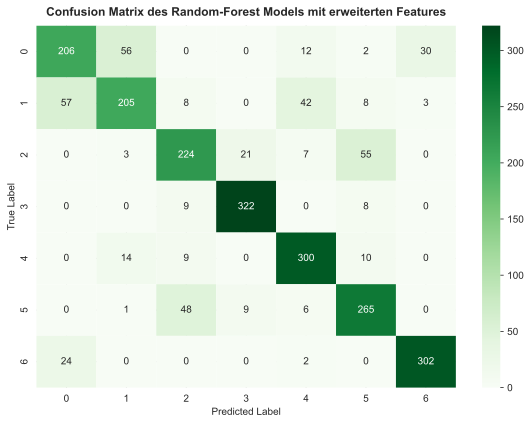

In [ ]:
# Third we use the best hyperparameters to train the model

# Get the best model out of the Optuna Database
loaded_study = optuna.load_study(study_name="RandomForest_optuna", storage="sqlite:///db.sqlite3")
best_trial = study.best_trial

# Get the best hyperparameters
best_hyperparameters = best_trial.params

# Create the model with the best hyperparameters
rf_clf = RandomForestClassifier(n_estimators = best_hyperparameters['n_estimators'], 
                                max_leaf_nodes = best_hyperparameters['max_leaf_nodes'], 
                                max_depth = best_hyperparameters['max_depth'], 
                                min_samples_leaf = best_hyperparameters['min_samples_leaf'], 
                                max_features = best_hyperparameters['max_features'], 
                                random_state=420)

# Perform 3-fold cross-validation
kf = KFold(n_splits=3, shuffle=True, random_state=420)
cv_scores = cross_val_score(rf_clf, X_train_ex, Y_train, cv=kf, scoring='accuracy', n_jobs=-1)

# Train the model on the entire training set
rf_clf.fit(X_train_ex, Y_train)

# Predict the test set
Y_pred_rf = rf_clf.predict(X_test_ex)

# Output CV and test results
print("##############")
print("Cross-Validation Accuracies: ", cv_scores)
print("Mean CV Accuracy: %.2f" % cv_scores.mean())
print("Test Accuracy: %.2f" % accuracy_score(Y_pred_rf, Y_test))
print("##############")

# Create the confusion matrix
confusion_matrix = sklearn.metrics.confusion_matrix(Y_test, Y_pred_rf)
# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix, annot=True, fmt='d', cmap='Greens')
# Set the title and labels
plt.title("Confusion Matrix des Random-Forest Models mit erweiterten Features", fontdict={'fontsize': 12, 'fontweight': 'bold'}, pad=10)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
# Adjust the layout
plt.tight_layout()
# Show the plot
plt.show()

---
### **HistGradientBoostingClassifier**

#### **HistGradientBoostingClassifier baseline with original data**
Das beste Baseline Model von der Baseline-Analyse

In [26]:
# Setup the classifier
clf = HistGradientBoostingClassifier(random_state=420)

##############
Cross-Validation Accuracies:  [0.85294118 0.84010271 0.84897292]
Mean CV Accuracy: 0.85
Test Accuracy: 0.85
##############


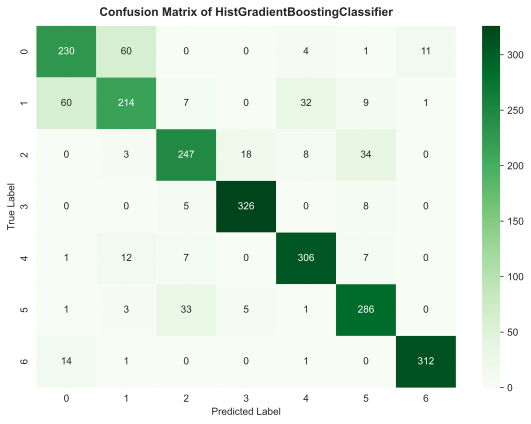

In [ ]:
# First we try a Random-Forest on original data

# Perform 3-fold cross-validation
kf = KFold(n_splits=3, shuffle=True, random_state=420)
cv_scores = cross_val_score(clf, X_train, Y_train, cv=kf, scoring='accuracy', n_jobs=-1)

# Train the model on the entire training set
clf.fit(X_train, Y_train)

# Predict the test set
Y_pred_clf= clf.predict(X_test)

# Output CV and test results
print("##############")
print("Cross-Validation Accuracies: ", cv_scores)
print("Mean CV Accuracy: %.2f" % cv_scores.mean())
print("Test Accuracy: %.2f" % accuracy_score(Y_pred_clf, Y_test))
print("##############")

# Predict the test set
Y_pred_hg = clf.predict(X_test)

# Create the confusion matrix
confusion_matrix = sklearn.metrics.confusion_matrix(Y_test, Y_pred_hg)
# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix, annot=True, fmt='d', cmap='Greens')
# Set the title and labels
plt.title("Confusion Matrix of HistGradientBoostingClassifier", fontdict={'fontsize': 12, 'fontweight': 'bold'}, pad=10)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
# Adjust the layout
plt.tight_layout()
# Show the plot
plt.show()

#### **HistGradientBoostingClassifier with newly generated features**
Test the model with the newly generated features to see if it improves.

##############
Cross-Validation Accuracies:  [0.85550887 0.84640523 0.85690943]
Mean CV Accuracy: 0.85
Test Accuracy: 0.85
##############


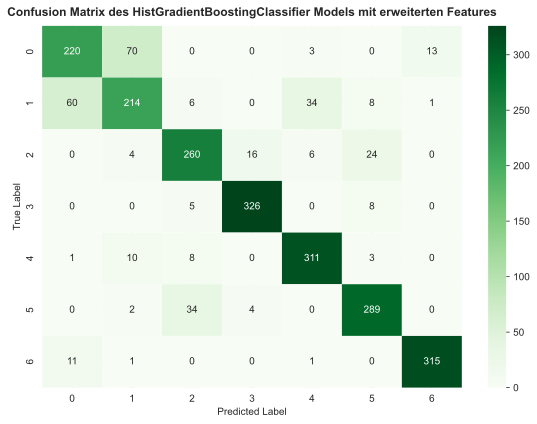

In [190]:
# Perform 3-fold cross-validation
kf = KFold(n_splits=3, shuffle=True, random_state=420)
cv_scores = cross_val_score(clf, X_train_ex, Y_train, cv=kf, scoring='accuracy', n_jobs=-1)

# Train the model on the entire training set
clf.fit(X_train_ex, Y_train)

# Predict the test set
Y_pred_clf= clf.predict(X_test_ex)

# Output CV and test results
print("##############")
print("Cross-Validation Accuracies: ", cv_scores)
print("Mean CV Accuracy: %.2f" % cv_scores.mean())
print("Test Accuracy: %.2f" % accuracy_score(Y_pred_clf, Y_test))
print("##############")

# Create the confusion matrix
confusion_matrix = sklearn.metrics.confusion_matrix(Y_test, Y_pred_clf)
# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix, annot=True, fmt='d', cmap='Greens')
# Set the title and labels
plt.title("Confusion Matrix des HistGradientBoostingClassifier Models mit erweiterten Features", fontdict={'fontsize': 12, 'fontweight': 'bold'}, pad=10)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
# Adjust the layout
plt.tight_layout()
# Show the plot
plt.show()

#### **HistGradientBoostingClassifier hyperparameteranalysis with Optuna**
Optuna performs hyperparameter analysis in exactly the same way as in RandomForest. 

In [ ]:
# Using Optuna to find the best hyperparameters for HistGradientBoostingClassifier
# Optuna-Objective-function
def objective(trial):
    # Define the hyperparameter search space
    learning_rate = trial.suggest_float("learning_rate", 0.05, 0.3)
    max_iter = trial.suggest_int("max_iter", 50, 500)
    max_leaf_nodes = trial.suggest_int("max_leaf_nodes", 15, 63)
    max_depth = trial.suggest_int("max_depth", 1, 20)
    min_samples_leaf = trial.suggest_int("min_samples_leaf", 1, 30)
    l2_regularization = trial.suggest_float("l2_regularization", 1e-3, 1)
    max_features = trial.suggest_float("max_features", 0.1, 1.0)
    max_bins = trial.suggest_int("max_bins", 50, 300)

    
    # HistGradientBoostingClassifier
    clf = HistGradientBoostingClassifier(
        learning_rate=learning_rate,
        max_iter=max_iter,
        max_leaf_nodes=max_leaf_nodes,
        max_depth=max_depth,
        min_samples_leaf=min_samples_leaf,
        l2_regularization=l2_regularization,
        max_features=max_features,
        max_bins=max_bins,

        random_state=420, # for reproducibility
    )
    
    # Cross-Validation-Score
    score = cross_val_score(clf, X_train, Y_train, cv=3, scoring="accuracy", n_jobs = -1)
    return score.mean()

try:
    optuna.study.delete_study(study_name="HistGrad_optuna", storage="sqlite:///db.sqlite3")
except:
    pass

# Create an Optuna study
study = optuna.create_study(direction="maximize", 
                            storage = "sqlite:///db.sqlite3",
                            study_name="HistGrad_optuna")  # Maximizing the accuracy and saving the optuna doc
study.optimize(objective, n_trials=200, n_jobs = -1)  # 50 trials (adjustable)

# Best parameters and results
print("Beste Parameter:", study.best_params)
print("Beste Accuracy:", study.best_value)

# Save the found parameters as csv
study.trials_dataframe().to_csv('results/HistGrad_optuna_results.csv')

#### **HistGradientBoostingClassifier hyperparameteranalysis brute-force Method**
Brute-force hyperparameter search for the two most important parameters (n_trees and learning_rate).

Despite CPU parallelisation, the programme takes a very long time to run (around 8 minutes on my computer), so the result is saved as a CSV file under HistGradient_results.csv.

In [ ]:
# Using parallel processing to find the best hyperparameters for HistGradientBoostingClassifier
# Setup the experiment for Hist Gradient Boosting Classifier
n_repeats = 20
median_iter = 100
median_learning = 0.1
results_list = []

# Funktion für einzelne Experimente
def run_experiment(i, j, X_train, Y_train, X_test, Y_test):
    # Berechnung von learning_rate und n_trees
    learning_rate = round(0.01 + (median_learning + (i - (n_repeats // 2)) * 0.01), 10)
    n_trees = 10 + median_iter + (j - (n_repeats // 2)) * 10 

    # Erstelle und trainiere das Modell
    clf = HistGradientBoostingClassifier(
        learning_rate=learning_rate,
        max_iter=n_trees,
        random_state=42
    )
    clf.fit(X_train, Y_train)
    y_pred = clf.predict(X_test)
    y_pred_train = clf.predict(X_train)

    # Rückgabe der Ergebnisse
    return {
        'Repeat': i + 1,
        'n_trees': n_trees,
        'learning_rate': learning_rate,
        'train_accuracy': accuracy_score(Y_train, y_pred_train),
        'test_accuracy': accuracy_score(Y_test, y_pred)
    }

# Parallele Verarbeitung des Experimentes
results_list = Parallel(n_jobs=-1, verbose=10)(delayed(run_experiment)(i, j, X_train, Y_train, X_test, Y_test) 
                                               for i in range(n_repeats) 
                                               for j in range(n_repeats))

# Konvertiere die Ergebnisse in einen DataFrame
results_df = pd.DataFrame(results_list)

# Speichere die Ergebnisse in einer CSV-Datei
results_df.to_csv('results/HistGrad_results.csv', index=False)

C:\Users\claud\AppData\Local\Temp\ipykernel_14760\3629821573.py:30: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


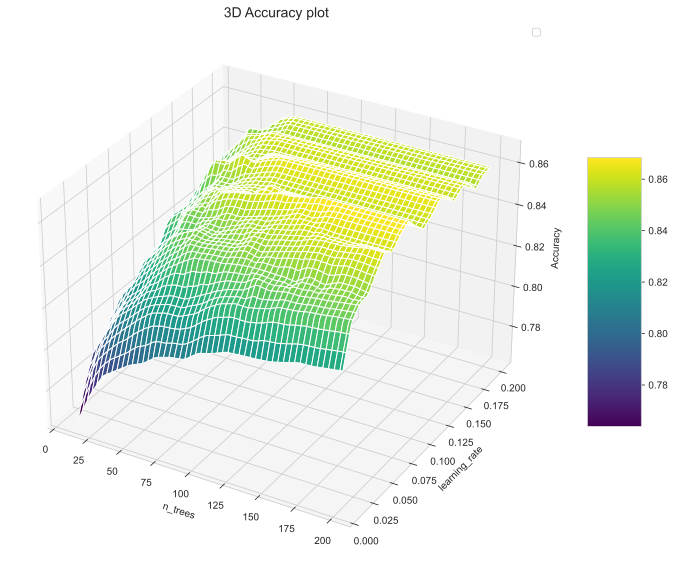

In [18]:
# Plot the data from above to get the results
# Read the csv file
results_df = pd.read_csv('results/HistGrad_results.csv')

# Extract the data
x = results_df['n_trees']
y = results_df['learning_rate']
z = results_df['test_accuracy']

# Create x and y arrays
xi = np.linspace(x.min(), x.max(), 100)
yi = np.linspace(y.min(), y.max(), 100)
xi, yi = np.meshgrid(xi, yi, indexing='ij')

# Create a grid with griddata and linear interpolation
zi = griddata((x, y), z, (xi, yi), method='linear')

# Plot the interpolated data as 3D
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

ax.plot_surface(xi, yi, zi, cmap='viridis')

# Add color bar to show the Z values
mappable = plt.cm.ScalarMappable(cmap='viridis')
mappable.set_array(zi)
fig.colorbar(mappable, ax=ax, shrink=0.5, aspect=5)

# Add legend and title
ax.legend()
ax.set_title('3D Accuracy plot', fontsize = 14)

# Set the labels
ax.set_xlabel('n_trees')
ax.set_ylabel('learning_rate')
ax.set_zlabel('Accuracy')

plt.tight_layout()
plt.show()

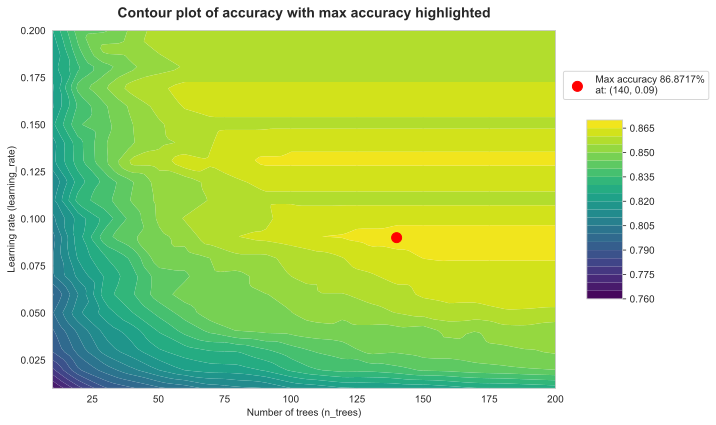

In [17]:
# Plot the data from above to get the results
# Read the csv file
results_df = pd.read_csv('results/HistGradient_results.csv')

# Extract the data
x = results_df['n_trees']
y = results_df['learning_rate']
z = results_df['test_accuracy']

# Create x and y arrays
xi = np.linspace(x.min(), x.max(), 100)
yi = np.linspace(y.min(), y.max(), 100)
xi, yi = np.meshgrid(xi, yi, indexing='ij')

# Create a grid with griddata and linear interpolation
zi = griddata((x, y), z, (xi, yi), method='linear')

# Find the point with the highest test_accuracy
max_index = results_df['test_accuracy'].idxmax()
max_x = results_df.loc[max_index, 'n_trees']
max_y = results_df.loc[max_index, 'learning_rate']
max_z = results_df.loc[max_index, 'test_accuracy']

# Create the figure and axis
fig, ax = plt.subplots()

# Change the size of the figure
fig.set_size_inches(10, 6)

# Use ContourF to plot the data
mappable = ax.contourf(xi, yi, zi, levels=20, cmap='viridis')
fig.colorbar(mappable, ax=ax, shrink=0.5, aspect=5)

# Mark the point with the highest accuracy
ax.scatter(max_x, max_y, color='red', s=100, label=f'Max accuracy {max_z*100:.4f}%\nat: ({max_x}, {max_y})')

# Set the title
ax.set_title('Contour plot of accuracy with max accuracy highlighted',fontweight = "bold", y = 1.02, fontsize = 14)

# Set the labels
ax.set_xlabel('Number of trees (n_trees)')
ax.set_ylabel('Learning rate (learning_rate)')

# Add legend
ax.legend()
# Change legend position
ax.legend(loc='upper right', bbox_to_anchor=(1.315, 0.9))

plt.tight_layout()
plt.show()

#### **HistGradientBoosting with newly generated features and best hyperparameters**
Test the model with the newly generated features and the best hyperparameters to hopefully create the best HistGradientBoosting model.

##############
Cross-Validation Accuracies:  [0.87021475 0.85971055 0.86764706]
Mean CV Accuracy: 0.87
Test Accuracy: 0.86
##############


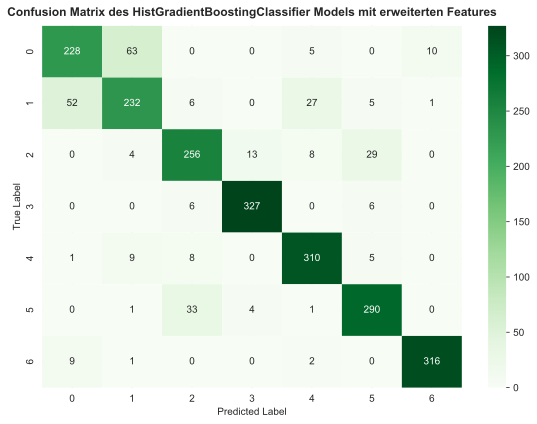

In [ ]:
# Load the study
study = optuna.load_study(study_name="HistGrad_optuna", storage="sqlite:///db.sqlite3")

# Get the best trial
best_trial = study.best_trial

# Get the best hyperparameters
best_hyperparameters = best_trial.params

# Use the best hyperparameters to train the model with indexing them as it is a dictionary
clf = HistGradientBoostingClassifier(learning_rate = best_hyperparameters['learning_rate'],
                                      max_iter = best_hyperparameters['max_iter'],
                                      max_leaf_nodes = best_hyperparameters['max_leaf_nodes'],
                                      max_depth = best_hyperparameters['max_depth'],
                                      min_samples_leaf = best_hyperparameters['min_samples_leaf'],
                                      l2_regularization = best_hyperparameters['l2_regularization'],
                                      max_features = best_hyperparameters['max_features'],
                                      max_bins = best_hyperparameters['max_bins'],
                                      random_state=420)

# Perform 3-fold cross-validation
kf = KFold(n_splits=3, shuffle=True, random_state=420)
cv_scores = cross_val_score(clf, X_train_ex, Y_train, cv=kf, scoring='accuracy', n_jobs=-1)

# Train the model on the entire training set
clf.fit(X_train_ex, Y_train)

# Predict the test set
Y_pred_clf= clf.predict(X_test_ex)

# Output CV and test results
print("##############")
print("Cross-Validation Accuracies: ", cv_scores)
print("Mean CV Accuracy: %.2f" % cv_scores.mean())
print("Test Accuracy: %.2f" % accuracy_score(Y_pred_clf, Y_test))
print("##############")

# Create the confusion matrix
confusion_matrix = sklearn.metrics.confusion_matrix(Y_test, Y_pred_clf)
# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix, annot=True, fmt='d', cmap='Greens')
# Set the title and labels
plt.title("Confusion matrix des HistGradientBoostingClassifier models mit erweiterten features", fontdict={'fontsize': 12, 'fontweight': 'bold'}, pad=10)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
# Adjust the layout
plt.tight_layout()
# Show the plot
plt.show()

---

## **Discussion and conclusion**

The *HistGradientBoostingClassifier* model works best with the newly created features and hyperparameter analysis using Optuna. This gives me the following scores:

############## \
Cross-Validation Accuracies:  [0.87021475 0.85971055 0.86764706] \
Mean CV Accuracy: 0.87 \
Test Accuracy: 0.86 \
##############

It solves the problem formulated there with a fairly high degree of accuracy and is quite capable of creating a classification that is much better than simply guessing at random.

The classification of `Cover_type_1` and `Cover_type_2` could be improved; these two target variables were very difficult to classify in almost all models, as can be seen from the confusion matrix. To solve this problem, it would probably be necessary to create a separate model that can distinguish between these two classes well.